# 02 · Bruit de $f$ et qualité du substitut $C$

Deux questions décident de la stratégie de recherche :

1. **Bruit.** Que vaut $\varsigma_s = \sqrt{\operatorname{Var}(\varepsilon_s)}$ dans $f(s) = F(s) + \varepsilon_s$ ? Combien d'évaluations faut-il pour estimer $F(s)$ ?
2. **Substitut.** $C$ (quelques µs) classe-t-il les placements comme $F$ (environ 0,1 s par évaluation) ?

**Protocole.**
- Par instance, 20 placements de qualité croissante : une permutation aléatoire, suivie de $K \in \lbrace 0, 5, \dots, 2000 \rbrace$ essais de descente sur $C$ (progression géométrique).
- Chaque placement est évalué $r = 10$ fois.

Les mesures sont enregistrées dans `results/noise_study.csv`. Mettre `RECOMPUTE = True` pour les refaire (environ 5 minutes).

In [1]:
import math
import time
import warnings

import numpy as np
import pandas as pd
from scipy import stats  # tests et corrélations statistiques

from goc.paths import RESULTS_ROOT
from optimizer import Problem, available_instances, distance_cost, load_instance
from optimizer.representation import random_permutation, random_swap_indices, swap, to_mapping

# Tableaux pandas affichés sur toute la largeur.
pd.set_option("display.width", 160)

In [2]:
# Réglages communs des graphiques : couleurs, polices, grilles.
import matplotlib as mpl
import matplotlib.pyplot as plt

# Palette de couleurs utilisée pour les séries (une couleur par algorithme ou par instance).
PALETTE = ["#3d72c4", "#d4692b", "#2a8a4f", "#c9443c", "#7a5cc2", "#8a8f98", "#c48a0a", "#2a9fb0", "#b04a8f"]
# Couleurs du cours : orange pour les qubits logiques, bleu pour les qubits physiques.
LOGICAL, LOGICAL_SOFT = "#d4692b", "#fdefe6"
PHYSICAL, PHYSICAL_SOFT = "#3d72c4", "#dfe8f5"
# Couleur selon la distance sur la puce : vert = voisins, jaune = distance 2, rouge = distance 3 ou plus.
DISTANCE_COLORS = {1: "#2a8a4f", 2: "#c48a0a", 3: "#c9443c"}
# Gris pour les textes secondaires et les grilles.
MUTED, GRID = "#656d76", "#e1e4e8"

# Application du style à tous les graphiques matplotlib du notebook.
mpl.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRID,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "legend.frameon": False,
    "figure.dpi": 110,
})


def subplot_grid(count, cols=3, width=4.4, height=3.0):
    """Crée une grille de `count` petits graphiques (cols par ligne) et cache les cases inutilisées."""
    # Nombre de lignes nécessaires (division arrondie au supérieur).
    rows = -(-count // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * width, rows * height), squeeze=False)
    # Les cases en trop (dernière ligne incomplète) sont masquées.
    for ax in axes.ravel()[count:]:
        ax.set_visible(False)
    return fig, axes.ravel()[:count]

## Paramètres

In [3]:
# Nombre de placements testés par instance.
MAPPINGS_PER_INSTANCE = 20
# Nombre de vraies évaluations de chaque placement.
RUNS_PER_MAPPING = 10
# Nombre maximal d'échanges de la descente sur le coût de distance (placements les plus optimisés).
MAX_DESCENT_STEPS = 2000
# Graine du générateur aléatoire (reproductibilité du choix des placements).
SEED = 2026
# False : on relit les mesures enregistrées si elles existent ; True : on refait toutes les mesures.
RECOMPUTE = False
# Fichier où les mesures sont enregistrées.
CACHE = RESULTS_ROOT / "noise_study.csv"

In [4]:
def surrogate_descent(instance, permutation, steps, rng):
    """Améliore une permutation par `steps` échanges aléatoires gardés s'ils ne dégradent pas le coût de distance."""
    current = permutation.copy()
    current_cost = distance_cost(instance, current[: instance.n])
    for _ in range(steps):
        candidate = swap(current, *random_swap_indices(instance.n, instance.m, rng))
        cost = distance_cost(instance, candidate[: instance.n])
        if cost <= current_cost:
            current, current_cost = candidate, cost
    return current


def spread_mappings(instance, count, rng, max_steps):
    """`count` placements de qualité variée : 0 échange (aléatoire) puis de plus en plus d'échanges de descente."""
    # Nombres d'échanges : 0, puis une progression géométrique de 5 à max_steps.
    levels = np.concatenate([[0], np.geomspace(5, max_steps, count - 1)]).astype(int)
    rows = []
    for mapping_id, steps in enumerate(levels):
        mapping = to_mapping(surrogate_descent(instance, random_permutation(instance.m, rng), int(steps), rng), instance.n)
        rows.append({"mapping_id": mapping_id, "descent_steps": int(steps), "mapping": mapping, "distance_cost": distance_cost(instance, mapping)})
    return rows


def measure(instance, mappings, runs):
    """Évalue chaque placement `runs` fois et renvoie un tableau avec une ligne par évaluation."""
    problem = Problem(instance)
    rows = []
    for item in mappings:
        for run in range(runs):
            rows.append({
                "instance_id": instance.instance_id,
                "mapping_id": item["mapping_id"],
                "descent_steps": item["descent_steps"],
                "distance_cost": item["distance_cost"],
                # Placement stocké en texte (plus simple à enregistrer en CSV et à afficher).
                "mapping": " ".join(map(str, item["mapping"])),
                "run": run,
                "cost": problem.fitness(item["mapping"]),
            })
    return pd.DataFrame(rows)

In [5]:
if CACHE.exists() and not RECOMPUTE:
    # Mesures déjà faites : on les relit (quelques millisecondes au lieu de plusieurs minutes).
    samples = pd.read_csv(CACHE)
    print(f"Loaded {len(samples)} evaluations from {CACHE}")
else:
    rng = np.random.default_rng(SEED)
    frames = []
    for instance_id in available_instances():
        instance = load_instance(instance_id)
        start = time.perf_counter()
        frames.append(measure(instance, spread_mappings(instance, MAPPINGS_PER_INSTANCE, rng, MAX_DESCENT_STEPS), RUNS_PER_MAPPING))
        print(f"instance {instance_id}: {MAPPINGS_PER_INSTANCE * RUNS_PER_MAPPING} evaluations in {time.perf_counter() - start:.0f} s")
    # Concaténation des tableaux de toutes les instances, puis enregistrement.
    samples = pd.concat(frames, ignore_index=True)
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    samples.to_csv(CACHE, index=False)

Loaded 1800 evaluations from C:\Users\hugo-\Desktop\Projet-GOC\results\noise_study.csv


## 1. Le bruit

Pour chaque placement, à partir de ses $r$ évaluations $f_1, \dots, f_r$ :

$$
\bar f = \frac1r \sum_{k=1}^{r} f_k \ \ (\text{estimation de } F(s)), \qquad
\hat\varsigma = \sqrt{\frac{1}{r-1} \sum_{k=1}^{r} (f_k - \bar f)^2}, \qquad
\mathrm{CV} = \frac{\hat\varsigma}{\bar f} \ \ (\text{bruit relatif})
$$

Sur les boîtes : une boîte par placement (ses 10 évaluations), triées par $C$ croissant (valeur sous la boîte).

In [6]:
def per_mapping_stats(samples):
    """Statistiques de chaque placement sur ses évaluations : moyenne, écart-type, min, max, étendue, CV."""
    stats_frame = samples.groupby(["instance_id", "mapping_id"]).agg(
        distance_cost=("distance_cost", "first"),
        descent_steps=("descent_steps", "first"),
        mean=("cost", "mean"),
        std=("cost", "std"),
        min=("cost", "min"),
        max=("cost", "max"),
        runs=("cost", "size"),
    ).reset_index()
    # Étendue : écart entre la meilleure et la pire évaluation.
    stats_frame["range"] = stats_frame["max"] - stats_frame["min"]
    # Coefficient de variation : bruit relatif à la moyenne.
    stats_frame["cv"] = stats_frame["std"] / stats_frame["mean"]
    return stats_frame


per_mapping = per_mapping_stats(samples)

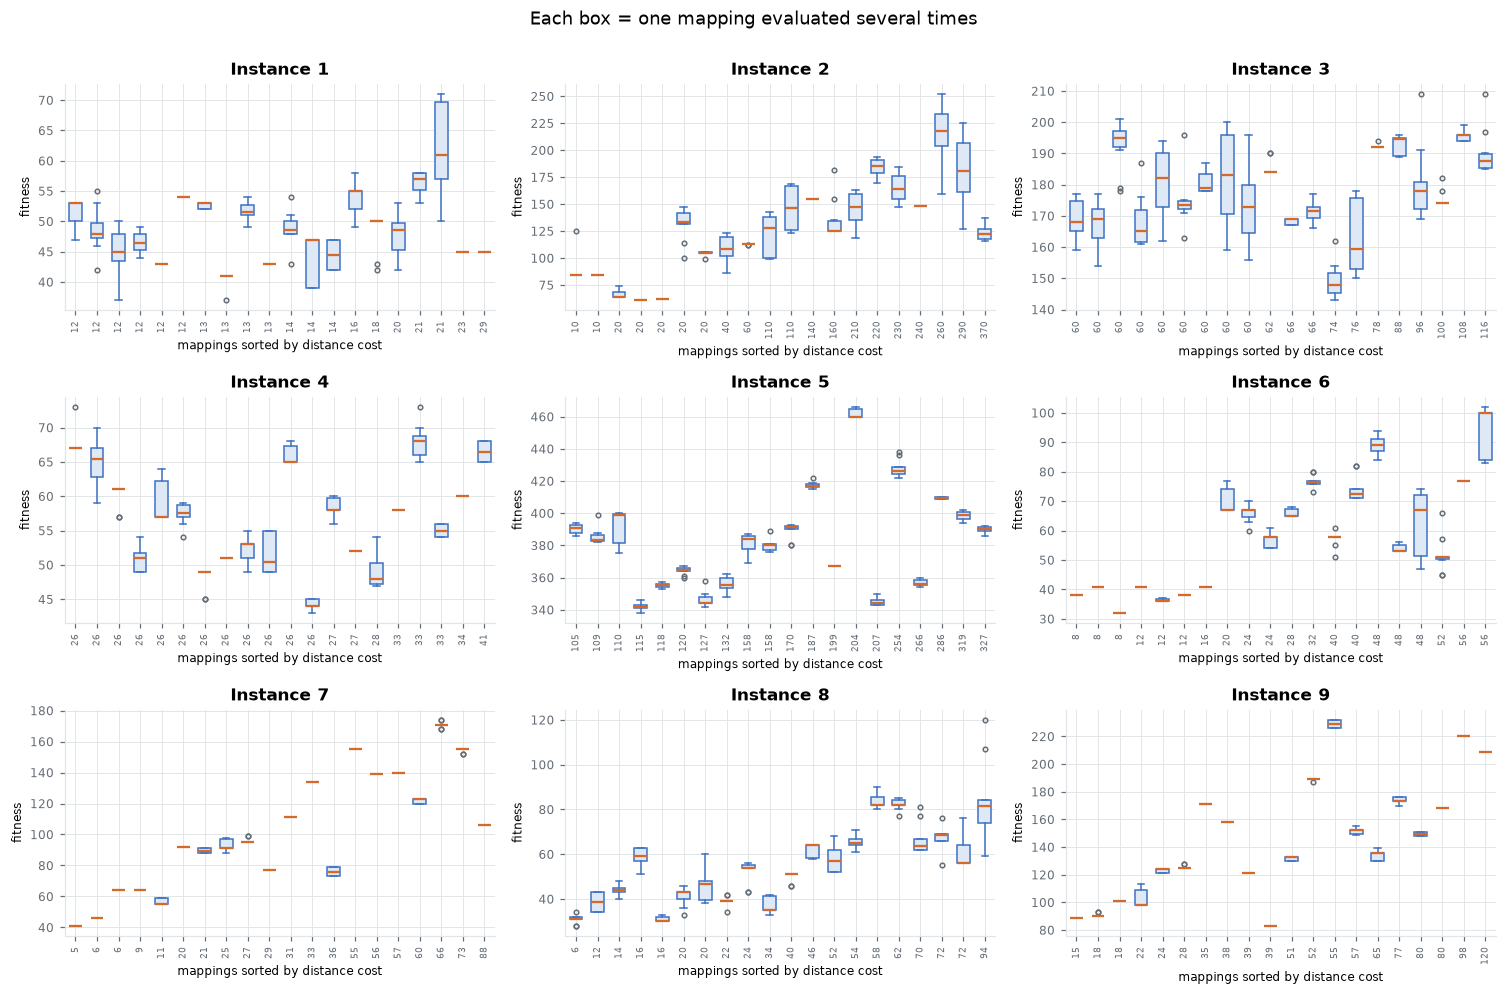

In [7]:
def plot_noise_boxplots(samples, per_mapping):
    """Une grille de boîtes à moustaches par instance : chaque boîte = les évaluations d'un placement."""
    instance_ids = sorted(samples["instance_id"].unique())
    fig, axes = subplot_grid(len(instance_ids), cols=3, width=4.6, height=3.0)
    for ax, instance_id in zip(axes, instance_ids):
        # Placements de l'instance triés par coût de distance.
        ordered = per_mapping[per_mapping["instance_id"] == instance_id].sort_values("distance_cost")
        data = [samples.loc[(samples["instance_id"] == instance_id) & (samples["mapping_id"] == mid), "cost"] for mid in ordered["mapping_id"]]
        ax.boxplot(data, widths=0.6, patch_artist=True,
                   boxprops={"facecolor": PHYSICAL_SOFT, "edgecolor": PHYSICAL},
                   medianprops={"color": LOGICAL, "linewidth": 1.5},
                   whiskerprops={"color": PHYSICAL}, capprops={"color": PHYSICAL},
                   flierprops={"markersize": 3, "markeredgecolor": MUTED})
        # Le coût de distance de chaque placement est écrit sous sa boîte.
        ax.set_xticks(range(1, len(ordered) + 1), ordered["distance_cost"].astype(int), rotation=90, fontsize=6)
        ax.set_title(f"Instance {instance_id}")
        ax.set_xlabel("mappings sorted by distance cost", fontsize=8)
        ax.set_ylabel("fitness", fontsize=8)
    fig.suptitle("Each box = one mapping evaluated several times", y=1.0)
    fig.tight_layout()
    return fig


plot_noise_boxplots(samples, per_mapping);

**Nombre d'évaluations nécessaires.** L'intervalle de confiance à 95 % de $F(s)$ a une demi-largeur $1{,}96\,\varsigma / \sqrt{r}$. Pour une précision $E$, il faut donc

$$
r \ge \Big(\frac{1{,}96\,\varsigma}{E}\Big)^2
$$

Le tableau donne cette valeur pour $E = 1$ (`runs_for_1`) et pour $E = 1\,\%$ de la moyenne (`runs_for_1pct`). On y trouve aussi `mean_std` ($\bar\varsigma$), `mean_cv`, `mean_range` (écart moyen entre la meilleure et la pire évaluation) et `noisy_share` (part des placements dont $f$ a varié au moins une fois).

In [8]:
def noise_summary(per_mapping, z=1.96):
    """Résumé du bruit par instance et nombre d'évaluations nécessaires pour une estimation précise."""
    table = per_mapping.groupby("instance_id").agg(
        mean_cost=("mean", "mean"),
        mean_std=("std", "mean"),
        max_std=("std", "max"),
        mean_cv=("cv", "mean"),
        mean_range=("range", "mean"),
        # Part des placements dont la fitness a varié au moins une fois (écart-type > 0).
        noisy_share=("std", lambda s: float((s > 0).mean())),
    )
    # Nombre d'évaluations pour connaître la moyenne à ±1 près avec 95 % de confiance : (z × std / 1)².
    table["runs_for_1"] = np.ceil((z * table["mean_std"]) ** 2).astype(int).clip(lower=1)
    # Même chose à ±1 % de la moyenne près.
    table["runs_for_1pct"] = np.ceil((z * table["mean_std"] / (0.01 * table["mean_cost"])) ** 2).astype(int).clip(lower=1)
    return table.round(3)


noise_table = noise_summary(per_mapping)
noise_table

,mean_cost,mean_std,max_std,mean_cv,mean_range,noisy_share,runs_for_1,runs_for_1pct
instance_id,,,,,,,,
1,48.600,2.227,7.709,0.045,6.25,0.75,20,81
2,127.030,10.636,34.414,0.076,30.35,0.75,435,270
3,177.630,6.777,16.833,0.039,19.85,1.00,177,56
4,57.000,1.598,3.542,0.028,4.15,0.80,10,31
5,382.805,3.524,11.590,0.009,10.00,0.95,48,4
6,58.135,2.561,11.448,0.038,6.95,0.65,26,75
7,101.350,0.866,4.012,0.009,1.95,0.40,3,3
8,54.920,4.728,17.521,0.085,13.95,1.00,86,285
9,146.020,1.314,7.246,0.010,2.95,0.55,7,4


### Le meilleur de $k$ évaluations (malédiction du vainqueur)

Une recherche garde le **minimum** observé. Pour $r$ mesures triées $f_{(1)} \le \dots \le f_{(r)}$, l'espérance du minimum de $k$ tirages sans remise est

$$
\mathbb{E}\Big[\min_{k} f\Big] = \frac{1}{\binom{r}{k}} \sum_{i=1}^{r} \binom{r-i}{k-1}\, f_{(i)}
$$

En effet, $f_{(i)}$ est le minimum du tirage si et seulement si on l'a tiré, ainsi que $k - 1$ valeurs parmi les $r - i$ plus grandes.

La courbe donne $(\bar f - \mathbb{E}[\min_k f]) / \bar f$ : de combien le meilleur de $k$ évaluations sous-estime $F(s)$. Un coût obtenu ainsi est **optimiste**, et une réévaluation le fera en général remonter.

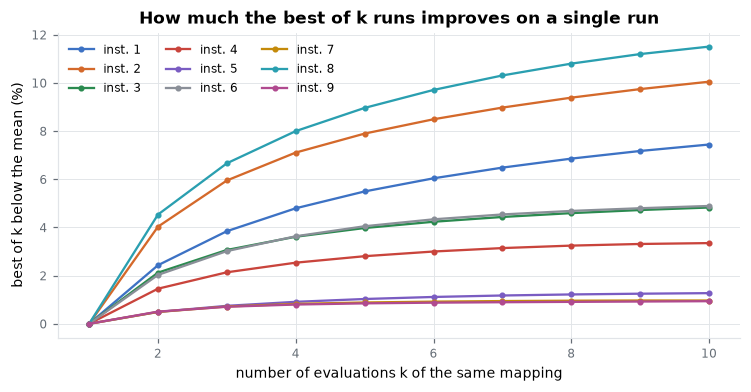

In [9]:
def expected_min_of_k(costs, k):
    """Espérance du minimum de k valeurs tirées sans remise parmi `costs` (formule des statistiques d'ordre)."""
    ordered = np.sort(np.asarray(costs, dtype=float))
    r = len(ordered)
    # Poids de la i-ème plus petite valeur : nombre de façons qu'elle soit le minimum d'un tirage de k valeurs.
    weights = np.array([math.comb(r - i, k - 1) for i in range(1, r + 1)], dtype=float)
    return float(np.dot(weights, ordered) / math.comb(r, k))


def min_of_k_curve(samples):
    """Pour chaque placement et chaque k : de combien le meilleur de k évaluations est sous la moyenne (en part de la moyenne)."""
    rows = []
    for (instance_id, mapping_id), group in samples.groupby(["instance_id", "mapping_id"]):
        costs = group["cost"].to_numpy()
        mean = costs.mean()
        for k in range(1, len(costs) + 1):
            expected = expected_min_of_k(costs, k)
            rows.append({"instance_id": instance_id, "mapping_id": mapping_id, "k": k, "relative_gain": (mean - expected) / mean})
    return pd.DataFrame(rows)


def plot_min_of_k(curve):
    """Une courbe par instance : gain moyen du meilleur de k évaluations par rapport à une seule."""
    fig, ax = plt.subplots(figsize=(8, 3.6))
    averaged = curve.groupby(["instance_id", "k"])["relative_gain"].mean().reset_index()
    for color, (instance_id, group) in zip(PALETTE * 2, averaged.groupby("instance_id")):
        ax.plot(group["k"], 100 * group["relative_gain"], marker="o", markersize=3, color=color, label=f"inst. {instance_id}")
    ax.set_xlabel("number of evaluations k of the same mapping")
    ax.set_ylabel("best of k below the mean (%)")
    ax.set_title("How much the best of k runs improves on a single run")
    ax.legend(ncol=3)
    return fig


plot_min_of_k(min_of_k_curve(samples));

## 2. Le coût de distance prédit-il la fitness ?

On compare l'ordre des 20 placements selon $C$ à leur ordre selon $\bar f$. La **corrélation de Spearman** est celle de Pearson calculée sur les rangs ; sans égalités, elle vaut

$$
\rho_S = 1 - \frac{6 \sum_{k} \delta_k^2}{N(N^2 - 1)}, \qquad \delta_k = \mathrm{rang}_C(s_k) - \mathrm{rang}_{\bar f}(s_k)
$$

- $\rho_S = 1$ : même classement ; $\rho_S \approx 0$ : aucun lien.
- **Pourquoi Spearman** : une métaheuristique n'utilise $C$ que pour **comparer** des placements. Seul l'ordre compte, et $\rho_S$ est invariant par toute transformation croissante.
- Pearson (linéaire) et la *p-value* de $\rho_S$ sont donnés à titre de contrôle.

In [10]:
def strength(rho):
    """Traduction d'une corrélation en mots (seuils usuels)."""
    if pd.isna(rho):
        return "undefined"
    value = abs(rho)
    for threshold, label in [(0.8, "very strong"), (0.6, "strong"), (0.4, "moderate"), (0.2, "weak")]:
        if value >= threshold:
            return label
    return "none"


def surrogate_correlation(per_mapping):
    """Corrélations (Spearman et Pearson) entre coût de distance et fitness moyenne, par instance."""
    rows = []
    for instance_id, group in per_mapping.groupby("instance_id"):
        # Les avertissements (par ex. valeurs constantes) sont masqués : le résultat vaut alors NaN.
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            spearman = stats.spearmanr(group["distance_cost"], group["mean"])
            pearson = stats.pearsonr(group["distance_cost"], group["mean"])
        rows.append({"instance_id": instance_id, "spearman": spearman.statistic, "p_value": spearman.pvalue, "pearson": pearson.statistic, "strength": strength(spearman.statistic)})
    return pd.DataFrame(rows).set_index("instance_id").round(4)


correlation_table = surrogate_correlation(per_mapping)
correlation_table

,spearman,p_value,pearson,strength
instance_id,,,,
1,0.1618,0.4954,0.1702,none
2,0.8143,0.0000,0.7444,very strong
3,0.2730,0.2443,0.3729,weak
4,0.2663,0.2565,0.3879,weak
5,0.3332,0.1511,0.3619,weak
6,0.7590,0.0001,0.7483,strong
7,0.8476,0.0000,0.8097,very strong
8,0.8363,0.0000,0.8380,very strong
9,0.7354,0.0002,0.7394,strong


Un point par placement : $C(s)$ en abscisse, $\bar f$ en ordonnée (barre = $\hat\varsigma$), droite = régression linéaire.

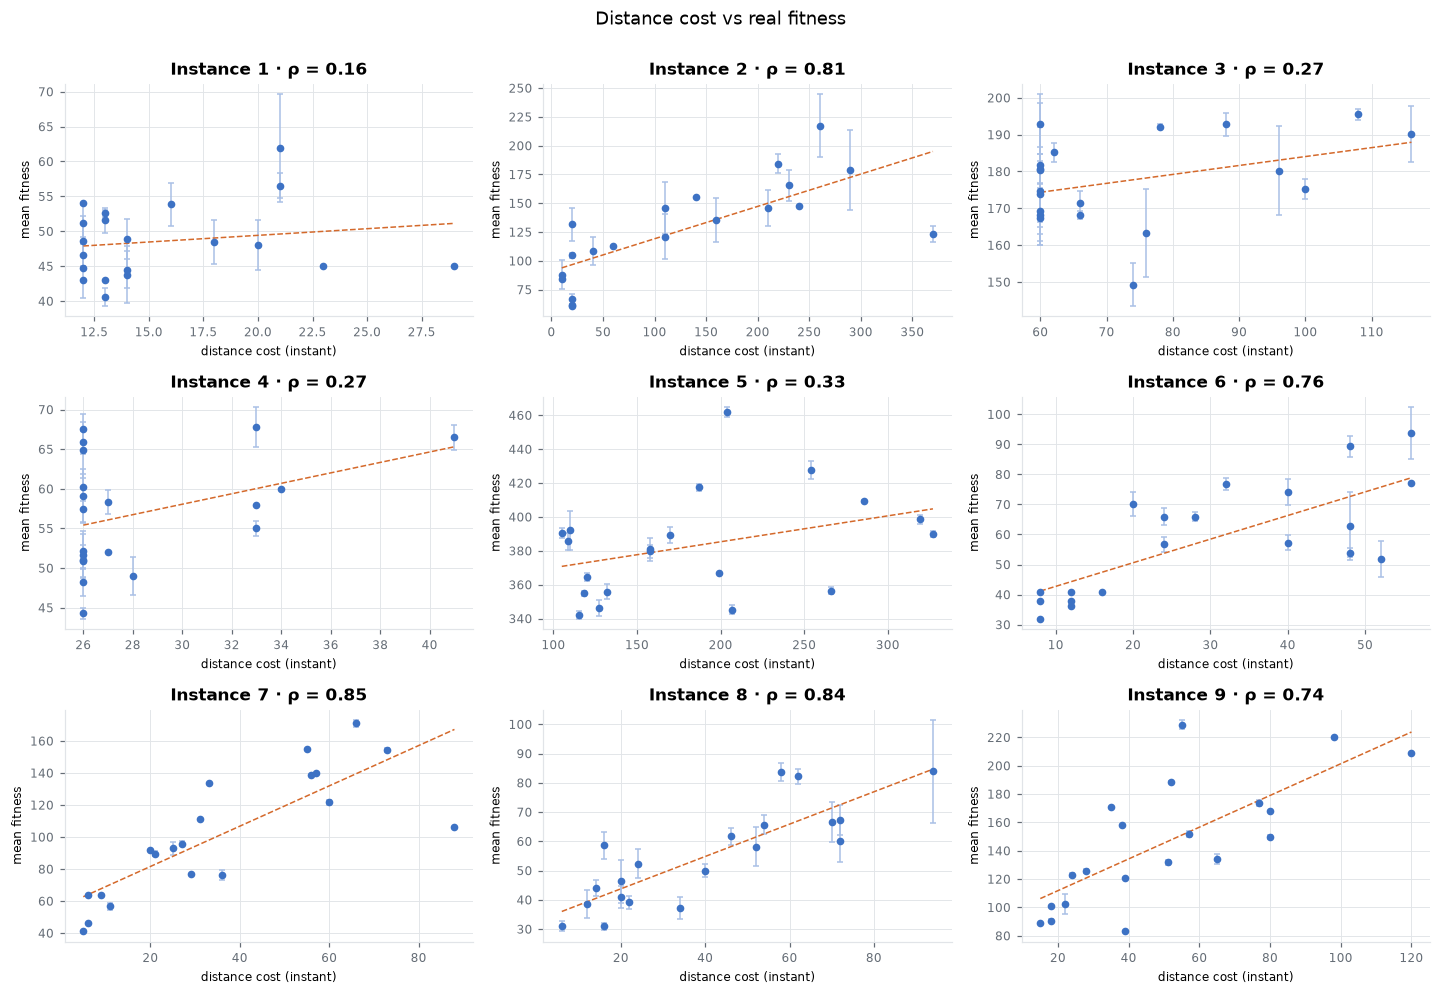

In [11]:
def plot_surrogate_scatter(per_mapping, correlation_table):
    """Nuage de points coût de distance / fitness moyenne pour chaque instance, avec la tendance linéaire."""
    instance_ids = sorted(per_mapping["instance_id"].unique())
    fig, axes = subplot_grid(len(instance_ids), cols=3, width=4.4, height=3.0)
    for ax, instance_id in zip(axes, instance_ids):
        group = per_mapping[per_mapping["instance_id"] == instance_id]
        # Point = moyenne ; barre verticale = écart-type.
        ax.errorbar(group["distance_cost"], group["mean"], yerr=group["std"].fillna(0), fmt="o", markersize=4, color=PHYSICAL, ecolor="#a9c0e6", elinewidth=1, capsize=2)
        if group["distance_cost"].nunique() > 1:
            # Droite de régression (polynôme de degré 1).
            slope, intercept = np.polyfit(group["distance_cost"], group["mean"], 1)
            xs = np.linspace(group["distance_cost"].min(), group["distance_cost"].max(), 50)
            ax.plot(xs, slope * xs + intercept, color=LOGICAL, linewidth=1, linestyle="--")
        ax.set_title(f"Instance {instance_id} · ρ = {correlation_table.loc[instance_id, 'spearman']:.2f}")
        ax.set_xlabel("distance cost (instant)", fontsize=8)
        ax.set_ylabel("mean fitness", fontsize=8)
    fig.suptitle("Distance cost vs real fitness", y=1.0)
    fig.tight_layout()
    return fig


plot_surrogate_scatter(per_mapping, correlation_table);

## Conclusions

Mesure du 11/11/2026 (20 placements × 10 évaluations par instance).

| Instance | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|---|---|
| $\bar\varsigma$ | 2,2 | 10,6 | 6,8 | 1,6 | 3,5 | 2,6 | 0,9 | 4,7 | 1,3 |
| CV | 4,6 % | 8,4 % | 3,8 % | 2,8 % | 0,9 % | 4,4 % | 0,9 % | 8,6 % | 0,9 % |
| $\rho_S(C, \bar f)$ | 0,16 | 0,81 | 0,27 | 0,27 | 0,33 | 0,76 | 0,85 | 0,84 | 0,74 |

**Bruit.**
- Fort sur les instances 2 et 8 : le meilleur de 10 évaluations est 10 à 12 % sous la moyenne.
- Faible sur 5, 7 et 9 (environ 1 %) : une évaluation y suffit presque.
- Conséquence : sur les instances bruitées, un coût trouvé pendant la recherche doit être **réévalué** avant d'être cru.

**Substitut.**
- $\rho_S \ge 0{,}74$ sur 2, 6, 7, 8 et 9. Sur ces circuits en chaîne ou en couches, la profondeur dépend surtout du nombre de `SWAP`, que $C$ estime bien. On peut y explorer massivement avec $C$ et n'évaluer avec $f$ que les meilleurs candidats.
- $\rho_S \le 0{,}33$ sur 1, 3, 4 et 5. Sur 1, 3 et 4, beaucoup de placements atteignent le plancher de $C$ (notebook 00, section 5) avec des fitness très différentes : $C$ trouve la bonne zone mais ne classe plus à l'intérieur. Sur 5 (portes de Toffoli enchaînées), la profondeur dépend de l'ordre des portes plus que des distances. La recherche fine doit donc se faire sur $f$.